# W5D3 — Temporal Convolutional Networks — Lab

**Week 5 · Day 3 · NLP Foundations** · Lab

Yesterday's GRU read a review one token at a time. That loop is what gives it a sense of order, and it
is also its two problems: it cannot be parallelised along the sequence, and its memory of the first
token has to survive every step after it.

Today's network reads a sequence with **convolutions**, the operation you used on images in week 4,
turned on its side: a filter slides along the tokens instead of across the pixels. Two changes make it
a sequence model. The convolution is **causal** — an output only sees the past. And it is **dilated** —
each layer skips further, so a short stack sees a long way back. That is a temporal convolutional
network, a TCN.

Its memory has a hard edge, the **receptive field**: how far back one output can see. You compute
it, measure it, and decide how wide it has to be.

**Time budget:** ~115 minutes. Sections 1–2 are the lab; Section 3 is a stretch you may finish at home.

<div dir="rtl" align="right">

# الأسبوع ٥ · اليوم ٣ — الشبكات الالتفافية الزمنية

**الأسبوع الخامس · اليوم الثالث · أساسيات معالجة اللغة** · معمل

قرأت GRU أمس المراجعة رمزًا بعد رمز. وتلك الحلقة هي ما يمنحها حسّ الترتيب، وهي أيضًا مشكلتاها: لا يمكن توزيعها
على التوازي على طول المتتالية، وذاكرتها للرمز الأول يجب أن تنجو من كل خطوة بعده.

وشبكة اليوم تقرأ المتتالية **بالالتفاف**، العملية التي استعملتها على الصور في الأسبوع الرابع، مُدارةً على جنبها:
مُرشِّح ينزلق على الرموز بدل البكسلات. وتغييران يجعلانها نموذج متتاليات. فالالتفاف **سببي** (causal) — لا يرى
المخرَج إلا الماضي. و**متّسع** (dilated) — كل طبقة تقفز أبعد، فيرى كومٌ قصير مسافةً طويلة إلى الوراء. وهذه
هي الشبكة الالتفافية الزمنية، TCN.

ولذاكرتها حدٌّ صارم، **مجال الاستقبال** (receptive field): إلى أيّ مدى يرى مخرَجٌ واحد إلى الوراء. تحسبه
وتقيسه، وتقرّر كم يجب أن يكون اتّساعه.

**الزمن المتوقّع:** نحو ١١٥ دقيقة. القسمان الأول والثاني هما المعمل، والقسم الثالث إضافي يمكن إكماله في المنزل.

</div>

> **This is your lab notebook.** Work through the hints — they tell you what to do and where
> to look, not what to type. Stuck for more than ten minutes on one task? Open the `_guided`
> version. That is not cheating; sitting stuck in silence is the only mistake. The full
> solution is released at the end of the day.

<div dir="rtl" align="right">

> **هذا دفتر المعمل الخاص بك.** اعمل وفق الإرشادات — فهي تخبرك بما يجب فعله وأين تبحث، لا بما
> تكتبه حرفيًا. إذا توقّفت أكثر من عشر دقائق عند مهمة واحدة فافتح نسخة `_guided`؛ هذا ليس غشًّا،
> والخطأ الوحيد هو أن تبقى متوقّفًا بصمت. ويُنشر الحل الكامل في نهاية اليوم.

</div>

## Learning objectives

By the end of this lab you can:

- Compute a causal 1-D convolution by hand, and show why ordinary "same" padding leaks the future.
- Get the tensor layout right: convolutions want `(batch, channels, time)`.
- Compute a receptive field from the kernel size and dilations, and confirm it with a gradient.
- Build a TCN residual block and prove it is causal.
- Say when a TCN beats an RNN on speed, and when it does not.

<div dir="rtl" align="right">

## أهداف التعلّم

في نهاية هذا المعمل تستطيع:

- أن تحسب التفافًا سببيًا أحادي البعد يدويًا، وتُظهر لماذا يُسرّب الحشو "same" العادي المستقبل.
- أن تضبط ترتيب أبعاد الموتر: الالتفاف يريد `(batch, channels, time)`.
- أن تحسب مجال الاستقبال من حجم النواة والاتّساعات، وتؤكّده بتدرّج.
- أن تبني كتلة TCN متبقّية (residual) وتُبرهن أنها سببية.
- أن تقول متى تتفوّق TCN على RNN في السرعة، ومتى لا.

</div>

## About the data

**Dataset:** `reviews_sentiment` on the week's split — `week5_split.json`, hash checked — tokenised
exactly as yesterday: the same 20,000-word vocabulary, padded to 128. Today's leaderboard row is
measured on the same 2,400 test reviews as the three before it.

Nothing downloads today. The slowest cell, task 2.4, trains the review classifier for five epochs, in
about a minute.

<div dir="rtl" align="right">

## عن البيانات

**مجموعة البيانات:** `reviews_sentiment` على تقسيم الأسبوع — `week5_split.json` مع التحقّق من البصمة —
مُرمَّزة تمامًا كالأمس: المعجم نفسه، ٢٠٬٠٠٠ كلمة، والحشو حتى ١٢٨. ويُقاس صفّ اليوم في اللوحة على مراجعات
الاختبار نفسها، ٢٬٤٠٠ مراجعة، كالصفوف الثلاثة قبله.

لا يُنزَّل شيء اليوم. وأبطأ خلية، المهمة ٢٫٤، تُدرّب مُصنّف المراجعات خمس حقب، في نحو دقيقة.

</div>

## Setup

<div dir="rtl" align="right">

## الإعداد

</div>

In [1]:
# === AIEP portable setup — works locally (conda) and on Google Colab ===============
try:
    import aiep
except ImportError:
    import subprocess, sys
    from pathlib import Path
    _local = next((p / "shared" for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "shared" / "aiep").is_dir()), None)
    if _local:
        sys.path.insert(0, str(_local))
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "git+https://github.com/0xRush/AIEP_Olo_student.git#subdirectory=shared"])
    import aiep

from aiep.env import ensure, seed_everything, versions
from aiep.data import get_dataset, load_artefact
from aiep.paths import ARTEFACT_DIR
from aiep.checks import check, check_close, report

ensure("matplotlib")
seed_everything(42)

import collections
import hashlib
import json
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
MAX_LEN, VOCAB_SIZE = 128, 20_000
NEGATION_PAIR = ["the service was good", "the service was not good"]
ORDER_PAIR = ["the food was good but the service was bad",
              "the service was good but the food was bad"]
torch.set_num_threads(4)
reviews = pd.read_parquet(get_dataset("reviews_sentiment"))
split = json.loads(load_artefact("week5_split.json").read_text(encoding="utf-8"))
check(hashlib.sha256(json.dumps({"train": split["train"], "test": split["test"]}).encode()).hexdigest()
      == split["sha256"], "week5_split.json must match its own hash", "يجب أن يطابق `week5_split.json` بصمته")
train, test = reviews.iloc[split["train"]], reviews.iloc[split["test"]]
print(f"train {len(train):,} | test {len(test):,} | split {split['sha256'][:12]}…")
print(versions())

📁 reviews_sentiment: using cached file at C:\Users\hp\AIEP_Olo_student\shared\data_cache\reviews_sentiment.parquet
ℹ️  Using the reference copy of week5_split.json from solutions_cache (you don't have a local one yet).
   نستخدم النسخة المرجعية من week5_split.json لعدم وجود نسخة محلية لديك.
train 9,600 | test 2,400 | split 6cca39ba38d2…
python 3.11.16 | numpy 2.0.2 | pandas 3.0.5 | scikit-learn 1.9.0 | torch 2.13.0+cpu | transformers 5.15.1


In [2]:
def load_board(days):
    """The leaderboard rows earlier days wrote (each day keeps its own file)."""
    rows = []
    for day in days:
        rows += json.loads(load_artefact(f"leaderboard_{day}.json").read_text(encoding="utf-8"))
    return rows


def show_board(rows):
    columns = ["day", "model", "n_train", "accuracy", "f1", "fit_s", "ms_per_1000", "size_mb",
               "negation_ok", "order_gap"]
    print(pd.DataFrame(rows)[columns].to_string(index=False))

## Section 1 — Warm-up: a convolution that only looks back  (≈25 min)

Everything here works.

### A causal convolution, by hand

A kernel of size 2 with weights `[0.5, 1.0]` reads two neighbouring values: `y_t = 0.5·x_{t−1} + 1.0·x_t`.
To keep the output as long as the input, pad **on the left only** with one zero. On `x = [1, 2, 3, 4]`:

| t | window | `y_t` |
|---|---|---|
| 1 | `[0, 1]` | `0.5·0 + 1·1` = **1.0** |
| 2 | `[1, 2]` | `0.5·1 + 1·2` = **2.5** |
| 3 | `[2, 3]` | **4.0** |
| 4 | `[3, 4]` | **5.5** |

Every output uses only the present and the past. The code checks the same numbers from `nn.Conv1d`
with the weights pinned.

<div dir="rtl" align="right">

## القسم الأول — الإحماء: التفافٌ لا ينظر إلا إلى الوراء (نحو ٢٥ دقيقة)

كل ما هنا يعمل.

### التفافٌ سببيّ، يدويًا

نواةٌ حجمها ٢ وأوزانها `[0.5, 1.0]` تقرأ قيمتين متجاورتين: `y_t = 0.5·x_{t−1} + 1.0·x_t`. ولتبقى المخرجات
بطول المدخلات، احشُ **من اليسار فقط** بصفر واحد. وعلى `x = [1, 2, 3, 4]`:

| t | النافذة | `y_t` |
|---|---|---|
| ١ | `[0, 1]` | `0.5·0 + 1·1` = **١٫٠** |
| ٢ | `[1, 2]` | `0.5·1 + 1·2` = **٢٫٥** |
| ٣ | `[2, 3]` | **٤٫٠** |
| ٤ | `[3, 4]` | **٥٫٥** |

كل مخرَج لا يستعمل إلا الحاضر والماضي. وتتحقّق الشيفرة من الأرقام نفسها في `nn.Conv1d` بالأوزان مثبّتة.

</div>

In [3]:
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
kernel = [0.5, 1.0]
padded = [0.0] + x.tolist()                                   # one zero on the left
BY_HAND = [kernel[0] * padded[t] + kernel[1] * padded[t + 1] for t in range(len(x))]
print("by hand :", BY_HAND)

conv = nn.Conv1d(in_channels=1, out_channels=1, kernel_size=2, bias=False)
with torch.no_grad():
    conv.weight.copy_(torch.tensor([[kernel]]))               # shape (out, in, kernel)
FROM_TORCH = conv(nn.functional.pad(x.view(1, 1, -1), (1, 0))).flatten()   # (batch, channels, time)
print("nn.Conv1d:", FROM_TORCH.tolist())

by hand : [1.0, 2.5, 4.0, 5.5]
nn.Conv1d: [1.0, 2.5, 4.0, 5.5]


### Two traps

**The layout.** Yesterday's embeddings came out as `(batch, time, features)`. A convolution reads
`(batch, channels, time)` — the features are the channels, and the time axis comes last. Feed it the
wrong one and you get an error at best. The cell shows the error and the one-line fix,
`.transpose(1, 2)`.

**"Same" padding leaks the future.** `nn.Conv1d(..., padding=1)` with a kernel of 3 pads both sides,
so the output at position `t` also reads `t+1`. Change the **last** input and watch an **earlier**
output move. For classifying a finished review that is harmless. For predicting what comes next, it is
cheating. Causal padding — left only — cannot leak.

<div dir="rtl" align="right">

### فخّان

**ترتيب الأبعاد.** خرجت تضمينات الأمس بالشكل `(batch, time, features)`. والالتفاف يقرأ `(batch, channels, time)`
— السمات هي القنوات، ومحور الزمن في الآخر. أعطِه الترتيب الخاطئ فتنال خطأً في أحسن الأحوال. تُظهر الخلية
الخطأ والإصلاح في سطر واحد، `.transpose(1, 2)`.

**الحشو "same" يُسرّب المستقبل.** `nn.Conv1d(..., padding=1)` بنواةٍ حجمها ٣ تحشو الجانبين، فيقرأ المخرَج عند
الموضع `t` الموضعَ `t+1` أيضًا. غيّر المُدخَل **الأخير** وراقب مخرجًا **سابقًا** يتحرّك. ولتصنيف مراجعةٍ مكتملة
لا ضرر في ذلك. أمّا للتنبّؤ بما يأتي بعدها فهو غشّ. والحشو السببي — من اليسار فقط — لا يستطيع التسريب.

</div>

In [4]:
embedded = torch.randn(8, MAX_LEN, 64)                       # (batch, time, features), as nn.Embedding gives
layer = nn.Conv1d(in_channels=64, out_channels=32, kernel_size=3)
try:
    layer(embedded)
except RuntimeError as error:
    print("without transpose:", str(error).split(",")[0])
print("with transpose   :", tuple(layer(embedded.transpose(1, 2)).shape), "= (batch, channels, time)")

without transpose: Given groups=1
with transpose   : (8, 32, 126) = (batch, channels, time)


In [5]:
torch.manual_seed(SEED)
same = nn.Conv1d(1, 1, kernel_size=3, padding=1)                # pads one zero on EACH side
causal = nn.Conv1d(1, 1, kernel_size=3)                         # we pad two zeros on the LEFT


def run_both(signal):
    s = signal.view(1, 1, -1)
    return same(s).flatten(), causal(nn.functional.pad(s, (2, 0))).flatten()


signal = torch.arange(1.0, 9.0)
changed = signal.clone()
changed[-1] = 100.0                                             # change only the LAST input
with torch.no_grad():
    (same_a, causal_a), (same_b, causal_b) = run_both(signal), run_both(changed)
SAME_LEAKS = not torch.equal(same_a[:-1], same_b[:-1])
CAUSAL_LEAKS = not torch.equal(causal_a[:-1], causal_b[:-1])
print(f"'same' padding: earlier outputs changed -> {SAME_LEAKS}")
print(f"causal padding: earlier outputs changed -> {CAUSAL_LEAKS}")

'same' padding: earlier outputs changed -> True
causal padding: earlier outputs changed -> False


## Section 2 — Core: four tasks  (≈60 min)

1. Dilation and the receptive field: compute it, then measure it.
2. A TCN residual block, and the proof that it is causal.
3. Parallel in time: when a TCN is faster than a GRU, and when it isn't.
4. A TCN on the reviews: the leaderboard row, both pairs, and long reviews.

<div dir="rtl" align="right">

## القسم الثاني — الأساسي: أربع مهام (نحو ٦٠ دقيقة)

١. الاتّساع ومجال الاستقبال: احسبه ثم قِسه.
٢. كتلة TCN متبقّية، والبرهان على أنها سببية.
٣. التوازي في الزمن: متى تكون TCN أسرع من GRU، ومتى لا.
٤. TCN على المراجعات: صفّ اللوحة، والزوجان، والمراجعات الطويلة.

</div>

### Task 2.1 — dilation and the receptive field

A causal convolution with kernel `k` and dilation `d` reads positions `t, t−d, …, t−(k−1)·d`. Stack
layers with dilations 1, 2, 4, 8 and each one reaches further, so the stack's **receptive field** — how
many inputs one output can depend on — is

`1 + (k − 1) · Σ d` = `1 + 2 · (1 + 2 + 4 + 8)` = **31** for `k = 3`.

Write `CausalConv1d` — a `Conv1d` that pads `(k − 1) · d` zeros on the left — then **measure** the
receptive field. The second cell is given: it stacks four of your layers with all weights set to 1,
feeds a sequence of 64, and takes the gradient of the last output with respect to every input. Exactly
31 positions are non-zero. Plot them
too: the gradient is largest in the middle of the window and tiny at its far edge, where only a few
paths through the layers reach. The window that counts in practice is narrower than the formula's.

<div dir="rtl" align="right">

### المهمة ٢٫١ — الاتّساع ومجال الاستقبال

يقرأ التفافٌ سببيّ بنواة `k` واتّساع `d` المواضعَ `t، t−d، …، t−(k−1)·d`. كدّس طبقات اتّساعاتها ١ و٢ و٤ و٨
فتصل كلٌّ منها أبعد، فيكون **مجال الاستقبال** للكوم — كم مُدخلًا يمكن أن يعتمد عليه مخرَج واحد —

`1 + (k − 1) · Σ d` = `1 + 2 · (1 + 2 + 4 + 8)` = **٣١** حين `k = 3`.

اكتب `CausalConv1d` — طبقة `Conv1d` تحشو `(k − 1) · d` صفرًا من اليسار — ثم **قِس** مجال الاستقبال. والخلية الثانية
معطاة: تُكدّس أربعًا من طبقاتك وكل أوزانها ١، وتُدخل متتالية طولها ٦٤، وتأخذ تدرّج المخرَج الأخير بالنسبة إلى كل
مُدخل. فتكون ٣١ موضعًا بالضبط غير صفرية. وارسمها أيضًا: التدرّج أكبر ما يكون في وسط النافذة وضئيل عند طرفها البعيد، حيث لا تصل إلا
مسارات قليلة عبر الطبقات. فالنافذة التي تُحسب في الواقع أضيق من نافذة الصيغة.

</div>

In [10]:
class CausalConv1d(nn.Module):
    """A Conv1d whose output at time t only sees inputs at t and before."""

    def __init__(self, in_channels, out_channels, kernel_size, dilation=1, bias=True):
        super().__init__()
        # TODO: Store the left padding (kernel_size - 1) * dilation and build the Conv1d with that dilation.
        # مهمة: احفظ الحشو الأيسر `(kernel_size - 1) * dilation` وابنِ `Conv1d` بذلك الاتّساع.
        super().__init__()
        self.left_pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size,
                              dilation=dilation, bias=bias)
    def forward(self, x):                       # x: (batch, channels, time)
        # TODO: Pad on the left only, then convolve.
        # مهمة: احشُ من اليسار فقط، ثم طبّق الالتفاف.
        x = nn.functional.pad(x, (self.left_pad, 0))   # left only
        return self.conv(x)
def receptive_field(kernel_size, dilations):
    return 1 + (kernel_size - 1) * sum(dilations)


DILATIONS = [1, 2, 4, 8]
RF_FORMULA = receptive_field(3, DILATIONS)
print(f"receptive field by formula: {RF_FORMULA}")

receptive field by formula: 31


receptive field measured: 31 inputs reach the last output


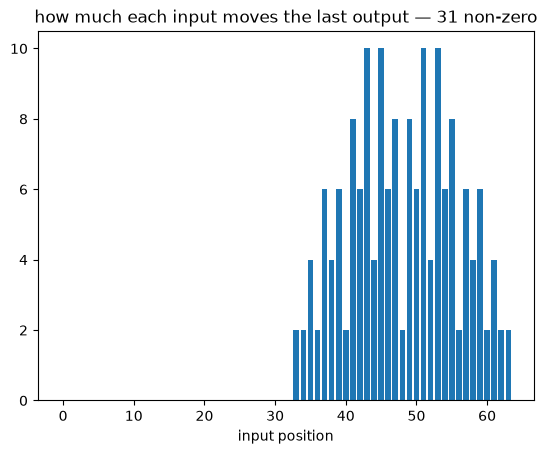

In [11]:
# Four of your layers, every weight 1 and no bias, so the gradient counts the paths from each input.
stack = nn.Sequential(*[CausalConv1d(1, 1, 3, d) for d in DILATIONS])
with torch.no_grad():
    for layer in stack:
        layer.conv.weight.fill_(1.0)
        layer.conv.bias.zero_()
inputs = torch.randn(1, 1, 64, requires_grad=True)
stack(inputs)[0, 0, -1].backward()
outputs = stack(inputs)
outputs[0, 0, -1].backward()  
GRADIENT = inputs.grad.flatten()
RF_MEASURED = int((GRADIENT != 0).sum())                     # inputs the last output depends on

print(f"receptive field measured: {RF_MEASURED} inputs reach the last output")
plt.bar(range(64), GRADIENT.numpy())
plt.title(f"how much each input moves the last output — {RF_MEASURED} non-zero")
plt.xlabel("input position")
plt.show()

### Task 2.2 — the TCN residual block

The standard block: two dilated causal convolutions, each followed by ReLU and dropout, and a
**residual** connection around both — the same skip connection as ResNet in week 4. When the number
of channels changes, the skip path needs a `1 × 1` convolution to match shapes.

Assert the shape after every step. Then the **causality proof**: change one input at time 50, and every
output before time 50 must stay exactly the same. A block of these with dilations 1, 2, 4, 8 has two
convolutions per block, so its receptive field is `1 + 2 · 2 · 15` = **61**.

<div dir="rtl" align="right">

### المهمة ٢٫٢ — كتلة TCN المتبقّية

الكتلة القياسية: التفافان سببيّان متّسعان، يتبع كلًّا منهما ReLU وdropout، ووصلة **متبقّية** حولهما — وصلة التخطّي
نفسها في ResNet في الأسبوع الرابع. وحين يتغيّر عدد القنوات يحتاج طريق التخطّي التفافًا `1 × 1` ليتطابق الشكلان.

تحقّق من الشكل بعد كل خطوة. ثم **برهان السببية**: غيّر مُدخلًا واحدًا عند الزمن ٥٠، فيجب أن يبقى كل مخرَج قبل
الزمن ٥٠ كما هو تمامًا. ولكوم من هذه الكتل باتّساعات ١ و٢ و٤ و٨ التفافان في كل كتلة، فمجال استقباله
`1 + 2 · 2 · 15` = **٦١**.

</div>

In [12]:
class TCNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout=0.1):
        super().__init__()
        self.conv1 = CausalConv1d(in_channels, out_channels, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_channels, out_channels, kernel_size, dilation)
        self.drop = nn.Dropout(dropout)
        self.skip = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        # TODO: conv1 -> ReLU -> dropout -> conv2 -> ReLU -> dropout, then add the skip path and apply ReLU.
        # مهمة: `conv1` ثم ReLU ثم dropout ثم `conv2` ثم ReLU ثم dropout، ثم أضِف طريق التخطّي وطبّق ReLU.
        out = self.drop(torch.relu(self.conv1(x)))     
        out = self.drop(torch.relu(self.conv2(out)))    
        return torch.relu(out + self.skip(x))         

class TCN(nn.Module):
    def __init__(self, in_channels, channels, dilations, kernel_size=3, dropout=0.1):
        super().__init__()
        blocks = [TCNBlock(in_channels if i == 0 else channels, channels, kernel_size, d, dropout)
                  for i, d in enumerate(dilations)]
        self.blocks = nn.Sequential(*blocks)
        self.receptive_field = 1 + 2 * (kernel_size - 1) * sum(dilations)

    def forward(self, x):                        # (batch, channels, time) -> (batch, channels, time)
        return self.blocks(x)

In [13]:
torch.manual_seed(SEED)
block = TCNBlock(16, 32, kernel_size=3, dilation=2).eval()
x = torch.randn(4, 16, 100)
SHAPES = {"input": tuple(x.shape), "conv1": tuple(block.conv1(x).shape),
          "skip": tuple(block.skip(x).shape), "block": tuple(block(x).shape)}
print(SHAPES)

tcn = TCN(16, 32, DILATIONS).eval()
x_changed = x.clone()
x_changed[:, :, 50] += 10.0
with torch.no_grad():
    before, after = tcn(x), tcn(x_changed)
IS_CAUSAL = torch.equal(before[:, :, :50], after[:, :, :50]) and not torch.equal(before, after)
print(f"receptive field {tcn.receptive_field} | outputs before t=50 unchanged: {IS_CAUSAL}")

{'input': (4, 16, 100), 'conv1': (4, 32, 100), 'skip': (4, 32, 100), 'block': (4, 32, 100)}
receptive field 61 | outputs before t=50 unchanged: True


### Task 2.3 — parallel in time

A GRU must finish step `t` before it can start step `t+1`. A TCN computes every time step of a layer
at once. Time one **training step** (forward and backward) of a 4-block TCN and of a GRU, both 64
wide, in two settings:

- **one long sequence**: batch 1, length 2,000;
- **a wide batch of short ones**: batch 32, length 500.

The TCN wins the first by a large factor: the GRU's 2,000-step loop is the bottleneck. In the second the
GRU's every step is a batch of 32 matrix products, the loop is amortised, and on a CPU the GRU can
come out ahead. "Convolutions are faster" is true when the sequence is long and the batch is small —
which is training on long documents and audio, and generating one sequence at a time.

<div dir="rtl" align="right">

### المهمة ٢٫٣ — التوازي في الزمن

يجب أن تُنهي GRU الخطوة `t` قبل أن تبدأ الخطوة `t+1`. أمّا TCN فتحسب كل خطوات الطبقة الزمنية دفعةً واحدة.
وقّت **خطوة تدريب** واحدة (أمامية وخلفية) لشبكة TCN من أربع كتل ولـGRU، كلتاهما بعرض ٦٤، في حالتين:

- **متتالية واحدة طويلة**: دفعة ١، وطول ٢٬٠٠٠؛
- **دفعة عريضة من متتاليات قصيرة**: دفعة ٣٢، وطول ٥٠٠.

تفوز TCN في الأولى بفارق كبير: فحلقة GRU ذات الألفي خطوة هي عنق الزجاجة. وفي الثانية تكون كل خطوة من GRU
دفعةً من ٣٢ جداء مصفوفة، فتتوزّع كلفة الحلقة، وقد تتقدّم GRU على المعالج. فعبارة «الالتفاف أسرع» صحيحة حين تكون
المتتالية طويلة والدفعة صغيرة — وهذا هو التدريب على الوثائق الطويلة والصوت، والتوليد متتاليةً واحدة في كل مرّة.

</div>

In [16]:
def training_step_ms(model, x, repeats=3):
    """Mean wall-clock of forward + backward, in milliseconds (one warm-up run first)."""
    # TODO: Run model(x).sum().backward() once to warm up, then time `repeats` more and return the mean ms.
    # مهمة: شغّل `model(x).sum().backward()` مرّةً للتسخين، ثم وقّت `repeats` مرّات أخرى وأعِد المتوسط بالمللي ثانية.
    model(x).sum().backward()                    # warm-up
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model(x).sum().backward()
        times.append((time.perf_counter() - start) * 1000)
    return sum(times) / len(times)


class GRUOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(64, 64, batch_first=True)

    def forward(self, x):                           # x: (batch, time, 64)
        return self.gru(x)[0]


torch.manual_seed(SEED)
tcn64, gru64 = TCN(64, 64, DILATIONS), GRUOnly()
SPEED = {}
for name, (batch, length) in {"one long sequence": (1, 2000), "wide batch of short ones": (32, 500)}.items():
    x = torch.randn(batch, length, 64)
    SPEED[name] = {"TCN ms": training_step_ms(lambda v: tcn64(v.transpose(1, 2)), x),
                   "GRU ms": training_step_ms(gru64, x)}
SPEED = pd.DataFrame(SPEED).T.round(1)
print(SPEED.to_string())

                          TCN ms  GRU ms
one long sequence           38.3   767.4
wide batch of short ones   295.1   269.6


### Task 2.4 — a TCN on the reviews

The classifier: `Embedding → TCN (64 channels, dilations 1, 2, 4, 8) → pool over time → Linear`. Its
receptive field is 61 tokens, about the length of a medium review.

The pooling is where padding bites again. A TCN produces an output at **every** position, padding
included. Take the **maximum over the real positions only**: set the padded positions to `−inf`
before the max, using each review's length. That way the model answers "did a strongly positive or
negative phrase appear anywhere?", which is what a sentiment classifier wants.

Train for five epochs (about a minute), add the leaderboard row, and run both sentence pairs. Then
look at the length buckets next to yesterday's GRU: the GRU lost several points on long reviews, and
the TCN barely loses any. Nothing has to survive a chain of steps — the max looks at every window of
the review directly.

<div dir="rtl" align="right">

### المهمة ٢٫٤ — TCN على المراجعات

المُصنّف: `Embedding ← TCN (٦٤ قناة، اتّساعات ١ و٢ و٤ و٨) ← تجميع على الزمن ← Linear`. ومجال استقباله ٦١ رمزًا،
نحو طول مراجعةٍ متوسطة.

وفي التجميع يعضّ الحشو مرّة أخرى. فـTCN تُخرج مخرجًا عند **كل** موضع، والحشو منها. خُذ **الأقصى على المواضع
الحقيقية وحدها**: اجعل المواضع المحشوّة `−inf` قبل الأقصى، مستعملًا طول كل مراجعة. وبهذا يُجيب النموذج عن
سؤال «هل ظهرت عبارة إيجابية أو سلبية قويّة في أي مكان؟»، وهو ما يريده مُصنّف المشاعر.

درّبه خمس حقب (نحو دقيقة)، وأضِف صفّ اللوحة، وشغّل زوجَي الجمل. ثم انظر فئات الطول بجانب GRU الأمس: خسرت GRU
بضع نقاط على المراجعات الطويلة، ولا تكاد TCN تخسر شيئًا. فلا شيء يجب أن ينجو من سلسلة خطوات — الأقصى ينظر إلى كل
نافذة في المراجعة مباشرة.

</div>

In [17]:
def tokenize(text):
    return re.sub(r"[^0-9a-z؀-ۿ\s']+", " ", text.lower()).split()


counts = collections.Counter(w for text in train.review_text for w in tokenize(text))
ITOS = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(VOCAB_SIZE - 2)]
STOI = {w: i for i, w in enumerate(ITOS)}


def encode(texts):
    """Token ids, right-padded with 0 to MAX_LEN, and the true length of each review."""
    ids = [[STOI.get(w, 1) for w in tokenize(t)][:MAX_LEN] or [1] for t in texts]
    x = torch.zeros(len(ids), MAX_LEN, dtype=torch.long)
    for i, seq in enumerate(ids):
        x[i, :len(seq)] = torch.tensor(seq)
    return x, torch.tensor([len(seq) for seq in ids])


X_train, len_train = encode(train.review_text)
X_test, len_test = encode(test.review_text)
y_train = torch.tensor(train.sentiment.to_numpy()).long()
y_test = torch.tensor(test.sentiment.to_numpy()).long()
print(f"vocabulary {len(ITOS):,} | X_train {tuple(X_train.shape)} | longest review {int(len_train.max())} tokens")

vocabulary 20,000 | X_train (9600, 128) | longest review 125 tokens


In [18]:
class ReviewTCN(nn.Module):
    def __init__(self, dilations=(1, 2, 4, 8)):
        super().__init__()
        self.embed = nn.Embedding(len(ITOS), 64, padding_idx=0)
        self.tcn = TCN(64, 64, list(dilations))
        self.out = nn.Linear(64, 2)

    def forward(self, x, lengths):
        states = self.tcn(self.embed(x).transpose(1, 2))        # (batch, 64, time)
        # TODO: Mask the padded positions (t >= length) with -inf, max over time, then classify.
        # مهمة: أخفِ المواضع المحشوّة (`t >= length`) بـ`-inf`، وخُذ الأقصى على الزمن، ثم صنّف.
        positions = torch.arange(states.size(2), device=states.device)   
        pad_mask = positions[None, :] >= lengths[:, None]        
        states = states.masked_fill(pad_mask[:, None, :], float("-inf"))
        pooled = states.max(dim=2).values                         
        return self.out(pooled)       

In [19]:
def fit_reviews(model, epochs, lr=2e-3):
    """Mini-batches of 64 over the training set; returns the seconds it took."""
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X_train))
        for i in range(0, len(order), 64):
            batch = order[i:i + 64]
            loss = nn.functional.cross_entropy(model(X_train[batch], len_train[batch]), y_train[batch])
            optimiser.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimiser.step()
        print(f"  epoch {epoch + 1}: test accuracy {accuracy(model):.4f}")
    return time.perf_counter() - start


def accuracy(model):
    model.eval()
    with torch.no_grad():
        return float((model(X_test, len_test).argmax(1) == y_test).float().mean())


def p_positive(model, sentences):
    model.eval()
    x, lengths = encode(sentences)
    with torch.no_grad():
        return torch.softmax(model(x, lengths), dim=1)[:, 1].numpy()

In [20]:
from sklearn.metrics import f1_score

torch.manual_seed(SEED)
review_tcn = ReviewTCN()
TCN_FIT_S = fit_reviews(review_tcn, epochs=5)
TCN_ACCURACY = accuracy(review_tcn)

review_tcn.eval()
start = time.perf_counter()
with torch.no_grad():
    tcn_predictions = review_tcn(X_test, len_test).argmax(1).numpy()
TCN_MS_PER_1000 = (time.perf_counter() - start) / len(X_test) * 1e6
p_pairs = p_positive(review_tcn, NEGATION_PAIR + ORDER_PAIR)

BOARD_D3 = [{
    "day": "D3", "model": "TCN (trained from scratch)", "n_train": len(X_train),
    "accuracy": round(TCN_ACCURACY, 4), "f1": round(f1_score(y_test.numpy(), tcn_predictions), 4),
    "fit_s": round(TCN_FIT_S, 1), "ms_per_1000": round(TCN_MS_PER_1000, 1),
    "size_mb": round(sum(p.numel() for p in review_tcn.parameters()) * 4 / 1e6, 2),
    "negation_ok": bool(p_pairs[0] > 0.5 > p_pairs[1]), "order_gap": round(float(abs(p_pairs[2] - p_pairs[3])), 4),
}]
for sentence, p in zip(NEGATION_PAIR + ORDER_PAIR, p_pairs):
    print(f"  p(positive) = {p:.4f}   {sentence}")
print()
show_board(load_board(["D1", "D2"]) + BOARD_D3)

  epoch 1: test accuracy 0.6729
  epoch 2: test accuracy 0.7337
  epoch 3: test accuracy 0.7658
  epoch 4: test accuracy 0.7833
  epoch 5: test accuracy 0.7962
  p(positive) = 0.9353   the service was good
  p(positive) = 0.0869   the service was not good
  p(positive) = 0.2350   the food was good but the service was bad
  p(positive) = 0.4364   the service was good but the food was bad

ℹ️  Using the reference copy of leaderboard_D1.json from solutions_cache (you don't have a local one yet).
   نستخدم النسخة المرجعية من leaderboard_D1.json لعدم وجود نسخة محلية لديك.
ℹ️  Using the reference copy of leaderboard_D2.json from solutions_cache (you don't have a local one yet).
   نستخدم النسخة المرجعية من leaderboard_D2.json لعدم وجود نسخة محلية لديك.
day                                   model  n_train  accuracy     f1  fit_s  ms_per_1000  size_mb  negation_ok  order_gap
 D1            TF-IDF + logistic regression     9600    0.8300 0.8286   0.31         23.6     0.37         True     0.00

In [21]:
buckets = pd.cut(len_test.numpy(), bins=[0, 40, 80, MAX_LEN], labels=["short (<40)", "medium", "long (80+)"])
BY_LENGTH = pd.Series(tcn_predictions == y_test.numpy()).groupby(buckets, observed=True).mean()
print("TCN accuracy by review length:\n", BY_LENGTH.round(3).to_string())

TCN accuracy by review length:
 short (<40)    0.800
medium         0.796
long (80+)     0.791


## Section 3 — Stretch: a TCN beyond text  (≈30 min)

TCNs are at least as common on signals as on text: sensor readings, audio, demand forecasts. The causal
padding is what makes them forecasters — the output at `t` never saw `t+1`.

A synthetic daily series: quiet weekdays and a busy weekend, a slow trend and noise. Train a TCN to predict tomorrow from
the past (the target is the input shifted by one), and compare its error against the **seasonal naive**
forecast — "tomorrow equals the same day last week", the baseline every forecaster must beat. Then
shrink the dilations until the receptive field is **shorter than a week**, and watch the TCN lose to the
naive forecast it could beat before: it can no longer see the cycle.

<div dir="rtl" align="right">

## القسم الثالث — إضافي: TCN خارج النص (نحو ٣٠ دقيقة)

شبكات TCN شائعة على الإشارات على الأقل بقدر شيوعها على النص: قراءات الحسّاسات، والصوت، وتوقّعات الطلب. والحشو
السببي هو ما يجعلها أدوات تنبّؤ — فالمخرَج عند `t` لم يرَ `t+1` قطّ.

سلسلة يومية اصطناعية: أيام عمل هادئة وعطلة نهاية أسبوع مزدحمة، واتّجاه بطيء، وضجيج. درّب TCN لتتنبّأ بالغد من الماضي (الهدف هو المُدخل
مُزاحًا بخطوة)، وقارن خطأها بتنبّؤ **الساذج الموسمي** — «الغد يساوي اليوم نفسه من الأسبوع الماضي»، وهو الأساس الذي
يجب أن يتجاوزه كل متنبّئ. ثم صغّر الاتّساعات حتى يصير مجال الاستقبال **أقصر من أسبوع**، وراقب TCN تخسر أمام
التنبّؤ الساذج الذي كانت تتجاوزه: لم تعُد ترى الدورة.

</div>

In [22]:
torch.manual_seed(SEED)
days = torch.arange(3000, dtype=torch.float32)
weekend = (days % 7 >= 5).float()                                # busy Saturdays and Sundays
series = weekend + 0.0002 * days + 0.2 * torch.randn(3000)
series = (series - series.mean()) / series.std()
train_part, test_part = series[:2500], series[2500:]


class Forecaster(nn.Module):
    def __init__(self, dilations, kernel_size=2):
        super().__init__()
        self.tcn = TCN(1, 16, dilations, kernel_size=kernel_size, dropout=0.0)
        self.out = nn.Conv1d(16, 1, 1)

    def forward(self, x):                            # (1, 1, time) -> next-step prediction at every t
        return self.out(self.tcn(x))


def forecast_error(dilations, kernel_size=2, steps=300):
    torch.manual_seed(SEED)
    model = Forecaster(dilations, kernel_size)
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-2)
    x, target = train_part[:-1].view(1, 1, -1), train_part[1:].view(1, 1, -1)
    for _ in range(steps):
        loss = nn.functional.mse_loss(model(x), target)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
    with torch.no_grad():
        prediction = model(series[:-1].view(1, 1, -1)).flatten()[2499:]
    return float((prediction - test_part).abs().mean()), model.tcn.receptive_field


SEASONAL_NAIVE = float((series[2493:-7] - test_part).abs().mean())
for dilations in [[1, 2, 4, 8], [1]]:
    error, rf = forecast_error(dilations)
    print(f"TCN, receptive field {rf:>2}: mean absolute error {error:.3f}")
print(f"seasonal naive (same day last week): {SEASONAL_NAIVE:.3f}")

TCN, receptive field 31: mean absolute error 0.376
TCN, receptive field  3: mean absolute error 0.609
seasonal naive (same day last week): 0.431


## Save your artefacts

- `leaderboard_D3.json` — today's row.

<div dir="rtl" align="right">

## احفظ آثارك

- `leaderboard_D3.json` — صفّ اليوم.

</div>

In [23]:
(ARTEFACT_DIR / "leaderboard_D3.json").write_text(json.dumps(BOARD_D3, indent=2), encoding="utf-8")
print("wrote leaderboard_D3.json")

wrote leaderboard_D3.json


## Sanity check

<div dir="rtl" align="right">

## فحص سلامة

</div>

In [24]:
check(BY_HAND == [1.0, 2.5, 4.0, 5.5] and torch.allclose(FROM_TORCH, torch.tensor(BY_HAND)),
      "the causal convolution must give [1.0, 2.5, 4.0, 5.5] by hand and from nn.Conv1d",
      "يجب أن يُعطي الالتفاف السببي `[1.0, 2.5, 4.0, 5.5]` يدويًا ومن `nn.Conv1d`")
check(SAME_LEAKS and not CAUSAL_LEAKS,
      "'same' padding must leak the last input into earlier outputs, and causal padding must not",
      "يجب أن يُسرّب الحشو `same` المُدخلَ الأخير إلى المخرجات السابقة، وألّا يُسرّبه الحشو السببي")
check(RF_MEASURED == RF_FORMULA == 31,
      f"the measured receptive field must equal the formula's 31 — got {RF_MEASURED} and {RF_FORMULA}",
      f"يجب أن يساوي مجال الاستقبال المقيس صيغة ٣١ — والناتج {RF_MEASURED} و{RF_FORMULA}")
check(IS_CAUSAL and SHAPES["block"] == (4, 32, 100),
      "the TCN must keep (batch, channels, time) and leave every output before t=50 unchanged",
      "يجب أن تُبقي TCN الشكل `(batch, channels, time)` وأن تترك كل مخرَج قبل t=50 كما هو")
check(SPEED.loc["one long sequence", "TCN ms"] < SPEED.loc["one long sequence", "GRU ms"],
      "on one long sequence the TCN's training step must be faster than the GRU's",
      "على متتالية واحدة طويلة يجب أن تكون خطوة تدريب TCN أسرع من خطوة GRU")
check(TCN_ACCURACY > 0.75,
      f"the review TCN must score above 0.75 on the test set — got {TCN_ACCURACY:.4f}",
      f"يجب أن تتجاوز TCN المراجعات ٠٫٧٥ على الاختبار — والناتج {TCN_ACCURACY:.4f}")
report()

──────────────────────────────────────────────────────────────────
  ✓  week5_split.json must match its own hash
  ✓  the causal convolution must give [1.0, 2.5, 4.0, 5.5] by hand and from nn.Conv1d
  ✓  'same' padding must leak the last input into earlier outputs, and causal padding must not
  ✓  the measured receptive field must equal the formula's 31 — got 31 and 31
  ✓  the TCN must keep (batch, channels, time) and leave every output before t=50 unchanged
  ✓  on one long sequence the TCN's training step must be faster than the GRU's
  ✓  the review TCN must score above 0.75 on the test set — got 0.7962
──────────────────────────────────────────────────────────────────
  ✅ All 7 checks passed. / اجتزت جميع الفحوصات (7).
──────────────────────────────────────────────────────────────────


## What's next

**W5D4 — Attention and the transformer block.** Two kinds of memory so far: the RNN's, which fades step
by step and is a lottery to train, and the TCN's, a fixed window you must make wide enough in advance.

Tomorrow's mechanism has no window and no chain. Every token looks at every other token in **one step**,
and decides how much of each to take. You compute it by hand on three vectors — the same three you fed
the RNN yesterday — then build the full transformer block, and put it through yesterday's memory task
at length 100, where the RNNs were a lottery.

<div dir="rtl" align="right">

## ما التالي

**الأسبوع ٥ اليوم ٤ — الانتباه وكتلة المحوّل.** نوعان من الذاكرة حتى الآن: ذاكرة RNN التي تبهت خطوةً بعد خطوة
وتدريبها يانصيب، وذاكرة TCN، نافذةٌ ثابتة يجب أن تجعلها واسعة بما يكفي مسبقًا.

وآلية الغد بلا نافذة وبلا سلسلة. كل رمز ينظر إلى كل رمز آخر في **خطوة واحدة**، ويقرّر كم يأخذ من كلٍّ منها.
تحسبها يدويًا على ثلاثة متّجهات — الثلاثة نفسها التي أدخلتها RNN أمس — ثم تبني كتلة المحوّل كاملة، وتُدخلها مهمة
ذاكرة الأمس بالطول ١٠٠، حيث كانت الشبكات المتكرّرة يانصيبًا.

</div>